# OGLE-2024-BLG-0010 — Monte Carlo validation
Run all cells in Colab. The notebook uses OGLE observation times and photometric uncertainties to simulate repeated observations of a single point-lens light curve. Set `LOCAL_PHOTOMETRY` to an uploaded OGLE file if the download is unavailable.

The generating values are the real-data grid minimum for the two scanned parameters and the refined-fit baseline magnitude. The simulations fix the peak time and blending fraction, use independent Gaussian flux errors, and refit the baseline for each trial. The Monte Carlo standard deviations test repeatability under those assumptions.

Compare the Monte Carlo scatter with the profile uncertainties from the real-data fit. The scatter is most useful when no fits land on grid edges and it remains stable on a finer grid. To halve each grid step while keeping the same bounds, halve the two step sizes and double the two half-step counts in Settings.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen
from google.colab import files

# Simulation settings
N_TRIALS = 1000
SEED = 2026
DATA_URL = "https://www.astrouw.edu.pl/ogle/ogle4/ews/2024/blg-0010/phot.dat"
LOCAL_PHOTOMETRY = None  # Or "phot.dat" if you upload the OGLE file to Colab.

T0 = 2460383.444  # HJD
U0_TRUE = 0.5056
TE_TRUE = 9.856  # days
BASELINE_I = 16.372161  # Refined-fit baseline in I-band magnitudes
PROFILE_SIGMA = (0.001963, 0.06914)  # Mean of lower and upper profile errors

# Grid centered on the generating parameters. Finer steps are configurable.
U0_STEP, U0_HALF_STEPS = 0.0002, 80
TE_STEP, TE_HALF_STEPS = 0.006, 100
OUTPUT = Path("monte_carlo_0010")


In [2]:
def load_photometry():
    if LOCAL_PHOTOMETRY is None:
        with urlopen(DATA_URL, timeout=45) as response:
            data = np.loadtxt(response, usecols=(0, 1, 2), ndmin=2)
    else:
        data = np.loadtxt(LOCAL_PHOTOMETRY, usecols=(0, 1, 2), ndmin=2)
    valid = np.isfinite(data).all(axis=1) & (data[:, 2] > 0)
    time, mag, mag_error = data[valid].T
    if time.size < 4:
        raise ValueError("At least four valid photometry rows are required.")
    if 0 < np.median(time) < 100_000:
        time = time + 2450000
    if not 2_000_000 < np.median(time) < 3_000_000:
        raise ValueError("Expected HJD or HJD minus 2450000.")
    return time, mag, mag_error

def magnification(time, u0, te):
    """Point-lens magnification, with t0 fixed and blending fraction equal to one."""
    u_sq = u0**2 + ((time - T0) / te)**2
    return (u_sq + 2) / np.sqrt(u_sq * (u_sq + 4))

def grid_fit_many(time, flux_samples, flux_error, u_axis, te_axis):
    """Fit each column of flux_samples, profiling the baseline at every grid point."""
    weighted_data = flux_samples / flux_error[:, None]
    total_square = np.einsum("ij,ij->j", weighted_data, weighted_data)
    trials = np.arange(flux_samples.shape[1])
    best_score = np.full(trials.size, -np.inf)
    best_u = np.empty(trials.size, dtype=int)
    best_te = np.empty(trials.size, dtype=int)
    best_base = np.empty(trials.size)

    # Reuse each batch of model shapes across all light curves.
    for start in range(0, len(u_axis), 4):
        u_batch = u_axis[start:start + 4]
        shape = magnification(time, u_batch[:, None, None], te_axis[None, :, None])
        weighted_shape = shape.reshape(-1, time.size) / flux_error
        norm = np.linalg.norm(weighted_shape, axis=1)
        projections = (weighted_shape / norm[:, None]) @ weighted_data

        # chi² = ||weighted_data||² - projection² for the optimal baseline.
        scores = projections**2
        winner = scores.argmax(axis=0)
        score = scores[winner, trials]
        better = score > best_score
        rows, cols = np.divmod(winner[better], len(te_axis))
        best_score[better] = score[better]
        best_u[better] = start + rows
        best_te[better] = cols
        best_base[better] = projections[winner[better], trials[better]] / norm[winner[better]]

    edge = ((best_u == 0) | (best_u == len(u_axis) - 1) |
            (best_te == 0) | (best_te == len(te_axis) - 1))
    return u_axis[best_u], te_axis[best_te], best_base, np.maximum(0, total_square - best_score), edge

def run_simulation():
    time, mag, mag_error = load_photometry()
    # Relative flux units set the generating baseline to 1.
    observed_flux = 10**(-0.4 * (mag - BASELINE_I))
    flux_error = 0.4 * np.log(10) * observed_flux * mag_error
    true_flux = magnification(time, U0_TRUE, TE_TRUE)
    rng = np.random.default_rng(SEED)
    simulated_flux = true_flux[:, None] + flux_error[:, None] * rng.standard_normal(
        (time.size, N_TRIALS)
    )
    u_axis = U0_TRUE + U0_STEP * np.arange(-U0_HALF_STEPS, U0_HALF_STEPS + 1)
    te_axis = TE_TRUE + TE_STEP * np.arange(-TE_HALF_STEPS, TE_HALF_STEPS + 1)
    start = perf_counter()
    u_fit, te_fit, baseline, chi, edge = grid_fit_many(
        time, simulated_flux, flux_error, u_axis, te_axis
    )
    reduced_chi = chi / (time.size - 3)
    print(f"{time.size} observation times | {N_TRIALS} simulations | "
          f"{u_axis.size * te_axis.size:,} grid points per simulation")
    print(f"Grid fit time: {perf_counter() - start:.2f} s")
    print(f"Fits at a grid boundary: {edge.sum()} / {N_TRIALS}")
    if np.any(edge):
        print("Widen the grid and rerun before interpreting the scatter.")
    print(f"Mean simulated reduced chi-square: {reduced_chi.mean():.4f}")

    OUTPUT.mkdir(parents=True, exist_ok=True)
    np.savetxt(OUTPUT / "fits.csv",
               np.column_stack((np.arange(1, N_TRIALS + 1), u_fit, te_fit,
                                baseline, chi, reduced_chi, edge)),
               delimiter=",", fmt=["%d", "%.7f", "%.7f", "%.9f", "%.7f", "%.7f", "%d"],
               header="trial,u0,tE_days,relative_baseline,chi2,chi2_reduced,at_grid_edge",
               comments="")

    fig, panels = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    for ax, values, truth, profile, label in zip(
        panels, (u_fit, te_fit), (U0_TRUE, TE_TRUE), PROFILE_SIGMA,
        (r"$u_0$", r"$t_E$ [days]")
    ):
        mean = values.mean()
        spread = values.std(ddof=1)
        # Compare the recovered mean with the simulation input.
        standard_error = spread / np.sqrt(values.size)
        n_sigma = abs(mean - truth) / standard_error if standard_error > 0 else np.nan
        print(f"{label}: true={truth:.6f}, mean={mean:.6f}, bias={mean-truth:+.6f}, "
              f"MC SD={spread:.6f}, profile sigma={profile:.6f}, ratio={spread/profile:.3f}")
        print(f"  Standard error of the mean={standard_error:.6g} | N_sigma={n_sigma:.2f}")
        ax.hist(values, bins=25, color="#35759a", edgecolor="white")
        ax.axvline(truth, color="#252525", label="Generating value")
        ax.axvline(mean, color="#b6532c", linestyle="--", label="Monte Carlo mean")
        ax.set(xlabel=label, ylabel="Simulated fits")
        ax.legend()
    fig.savefig(OUTPUT / "parameter_distributions.png", dpi=180)
    plt.show()


428 observation times | 1000 simulations | 32,361 grid points per simulation
Grid fit time: 2.54 s
Fits at a grid boundary: 0 / 1000
Mean simulated reduced chi-square: 1.0003
$u_0$: true=0.505600, mean=0.505557, bias=-0.000043, MC SD=0.001985, profile sigma=0.001963, ratio=1.011
  Standard error of the mean=6.27624e-05 | N_sigma=0.69
$t_E$ [days]: true=9.856000, mean=9.857926, bias=+0.001926, MC SD=0.070577, profile sigma=0.069140, ratio=1.021
  Standard error of the mean=0.00223183 | N_sigma=0.86


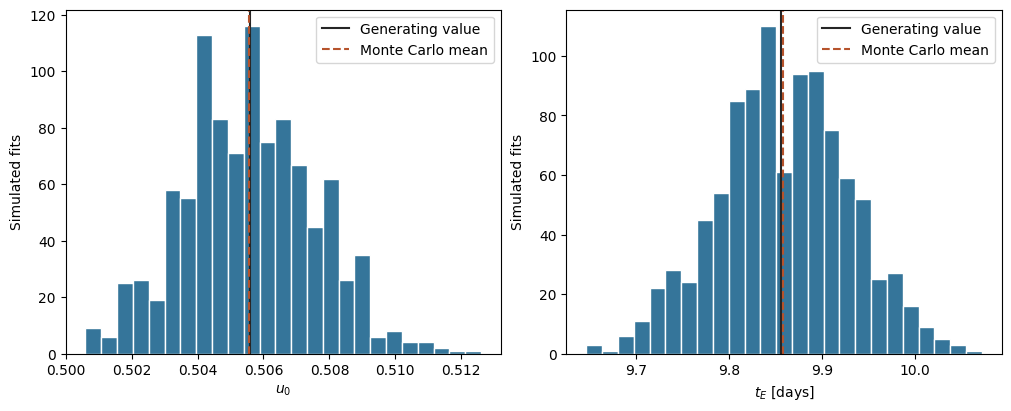

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
run_simulation()
files.download("/content/monte_carlo_0010/fits.csv")